# Inside the early-fusion model: embeddings, attention, and how missing, special and snapshot inputs are used

This notebook opens up the trained early-fusion model from `03_demo_early_fusion.ipynb`. It is organised around the path an input takes through the model, and at each stage asks one question.

```
 ① cell          e(v,t) = 1[regular]·(w·x+b) + E_state[s]      missing / special = a learned vector
 ② patch token   concat P cells → linear → d_model
 ③ grid encoder  ┌ attention across VARIABLES (inside each patch column)  ─┐ × L layers
                 └ attention across TIME      (inside each variable row)  ─┘
                 2-D CLS grid: [CLS global] [CLS time_n] (row 0) · [CLS var_v] (column 0)
                 → CLS_ts
 ④ snapshot      PLE vector of each variable → own linear → token → [CLS] + transformer → CLS_snapshot
 ⑤ head          MLP( [CLS_ts , CLS_snapshot] ) → ŷ
```

| stage | question | view | function (`tsfusion.interpret` / `tsfusion.viz`) |
|---|---|---|---|
| ① | Where do missing and special values sit relative to observed values? | cell-embedding map, state similarity | `cell_embedding_map`, `state_similarity` |
| ③④ | Does the record embedding organise by target, by missingness, by snapshot variables? | PCA of `CLS_ts` and `CLS_snapshot` | `collect_interpretation`, `pca_2d` |
| ④ | How is a snapshot variable's value range laid out? | token embeddings per snapshot variable | `InterpretationResult.snapshot_tokens` |
| ③ | For one record, which (variable, time) patches feed the prediction? | attention rollout to the global CLS, with missing/special patches marked | `run_with_attention`, `cls_rollout` |
| ③ | What does each attention stage do? | variable-attention and time-attention matrices | `AttentionMaps.var`, `.time` |
| ③ | Across all records, do missing/special patches get more or less weight than regular ones? | relevance lift by patch type | `relevance_by_category` |
| ④ | Which snapshot variables does the snapshot CLS read? | CLS → snapshot attention, snapshot rollout | `snapshot_cls_attention`, `snapshot_rollout` |
| ⑤ | What does the prediction actually depend on? | branch ablation, permutation importance (time-series and snapshot variables on one scale), state probe | `modality_ablation`, `permutation_importance`, `state_probe` |

**Attention shows where the model looks, not what it uses.** Sections 2–4 describe information flow. Section 5 changes the inputs and measures the predictions, which is the evidence for importance. Read the two together.

In [1]:
import sys, math
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))
from tsfusion import (ModelConfig, TrainConfig, RawData, Preprocessor, Trainer, long_df_to_array,
                      group_columns_by_prefix, build_state, default_target_mode, load_checkpoint,
                      regression_metrics)
from tsfusion import interpret as I
from tsfusion import viz as Z
from tsfusion.synthetic import make_synthetic_dataset

Z.use_style()
DEVICE = "cuda:0" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| device", DEVICE)

torch 2.15.0+cu132 | device cpu


## 0. Data and the trained early-fusion model

This uses the same synthetic data and split as notebooks 01–03. The model is the best early-fusion checkpoint (lowest validation RMSE) among the runs of notebook 03. If those runs aren't present, a small model is trained here.

For your data, point `CKPT` at your `best_model.pt` and build `val_raw` with your loader. Everything below uses only the model, the fitted preprocessor (stored in the checkpoint) and `RawData`.

In [2]:
data = make_synthetic_dataset(n_records=6000, n_vars=8, n_special_codes=3, seed=0)
var_names, time_steps, K = data["var_names"], data["time_steps"], data["n_special_codes"]
ple_groups = group_columns_by_prefix(data["snapshot_ple_df"].columns)
ple_cols = [c for _, cols in ple_groups for c in cols]
snap_names = [name for name, _ in ple_groups]
group_sizes = [len(cols) for _, cols in ple_groups]

def to_raw(ids):
    kw = dict(value_cols=var_names, record_ids=ids, time_steps=time_steps)
    x, _ = long_df_to_array(data["ts_df"], **kw)
    miss, _ = long_df_to_array(data["missing_df"], fill_value=1, **kw)
    spec, _ = long_df_to_array(data["special_df"], fill_value=0, **kw)
    return RawData(x, miss, spec.astype(np.int64), data["snapshot_ple_df"].loc[ids, ple_cols].to_numpy(),
                   data["y"].loc[ids].to_numpy())

train_raw, val_raw = to_raw(data["train_ids"]), to_raw(data["val_ids"])

runs = sorted((REPO / "runs" / "demo_early_fusion").glob("*/metrics.csv"))
if runs:
    best_run = min(runs, key=lambda p: pd.read_csv(p).val_rmse.min()).parent
    CKPT = best_run / "best_model.pt"
else:                                   # notebook 03 not run: train a small early-fusion model
    prep0 = Preprocessor(K, group_sizes, target_mode=default_target_mode("tweedie")).fit(train_raw)
    mcfg = ModelConfig(n_vars=len(var_names), n_special_codes=K, snapshot_group_sizes=group_sizes,
                       d_model=32, ff_mult=2, missing_fusion="early")
    tcfg = TrainConfig(loss="tweedie", tweedie_power=1.5, max_epochs=25, early_stopping_patience=6,
                       warmup_steps=38, device=DEVICE, verbose=False,
                       output_dir=str(REPO / "runs" / "demo_interpret_model"))
    Trainer(mcfg, tcfg, prep0).fit(prep0.transform(train_raw), prep0.transform(val_raw))
    CKPT = Path(tcfg.output_dir) / "best_model.pt"

model, prep, train_cfg, ckpt = load_checkpoint(str(CKPT), device=DEVICE)
val = prep.transform(val_raw)
cfg = model.cfg
P, S_ = cfg.patch_len, cfg.patch_stride
patch_labels = [f"{1 + n * S_}-{n * S_ + P}" for n in range(model.n_patches)]
print(f"checkpoint: {CKPT.relative_to(REPO)} (epoch {ckpt['epoch']}, {train_cfg.loss}"
      f"{f' p={train_cfg.tweedie_power}' if train_cfg.loss == 'tweedie' else ''}, fusion={cfg.missing_fusion})")
print(f"V={cfg.n_vars} variables, T={cfg.n_steps} steps -> Np={model.n_patches} patches; "
      f"grid {(cfg.n_vars + 1)} x {(model.n_patches + 1)} tokens; {len(cfg.snapshot_group_sizes)} snapshot variables")
assert cfg.missing_fusion in ("early", "hybrid"), "this notebook is written for value-aware tokens"

checkpoint: runs/demo_early_fusion/tweedie_p1.2/best_model.pt (epoch 26, tweedie p=1.2, fusion=early)
V=8 variables, T=11 steps -> Np=9 patches; grid 9 x 10 tokens; 5 snapshot variables


## 1. Cell embeddings: where missing and special values live

Every cell becomes a small vector before patching. A regular cell lies on a **line**: `w·x + b + E[regular]` moves linearly with the standardised value `x`. Missing and each special code are **single learned points**, shared by all variables.

The PCA map below shows where those points sit relative to the line of observed values:
* a point **on or near the line** means the state is treated much like "an observed value of about that size", for example missing ≈ a low value;
* a point **far off the line** means the state carries its own information, which the network can tell apart from any observed value.

The similarity matrix gives the same comparison in the full embedding space.

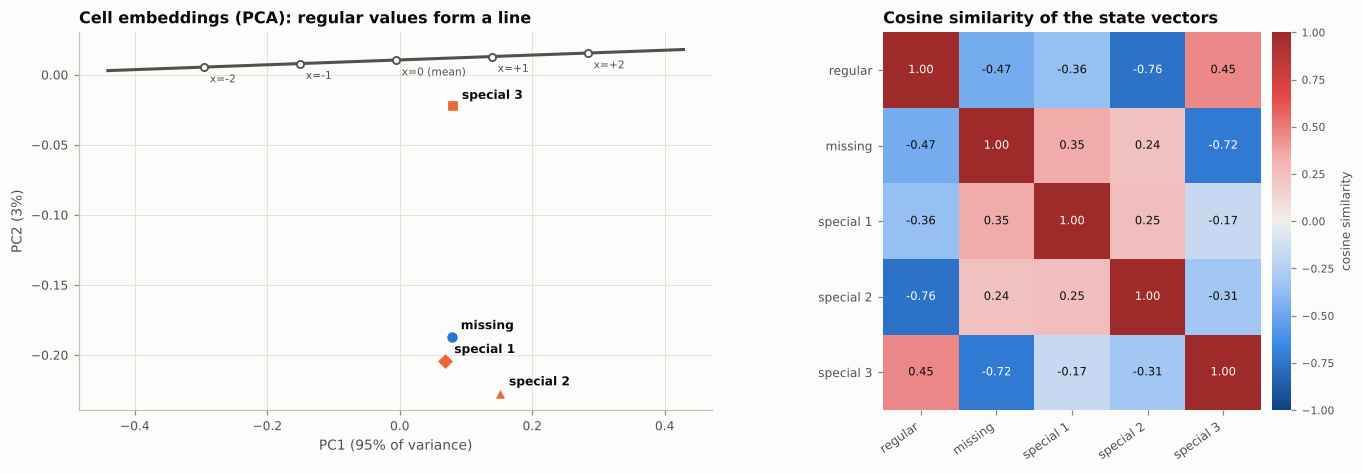

,closest x on the line,distance from the line (in SDs of x)
state,,
missing,0.6,1.58
special 1,0.5,1.68
special 2,1.1,1.83
special 3,0.6,0.88


In [3]:
cmap = I.cell_embedding_map(model)
sim = I.state_similarity(model)
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.4), gridspec_kw={"width_ratios": [1.15, 1]})
Z.plot_cell_embedding_map(ax[0], cmap, "Cell embeddings (PCA): regular values form a line")
Z.plot_similarity(fig, ax[1], sim, "Cosine similarity of the state vectors")
plt.tight_layout(); plt.show()

# distance of each state to the nearest point on the regular-value line, in units of the line's
# length per standard deviation of x (how many "SDs of value" away the state is)
reg, xs = cmap["regular"], cmap["x_values"]
per_sd = np.linalg.norm(reg[-1] - reg[0]) / (xs[-1] - xs[0])
rows = []
for k, vec in cmap["states"].items():
    d = np.linalg.norm(reg - vec, axis=1)
    rows.append({"state": I.state_names(K)[k], "closest x on the line": round(float(xs[d.argmin()]), 2),
                 "distance from the line (in SDs of x)": round(float(d.min() / per_sd), 2)})
pd.DataFrame(rows).set_index("state")

**What this model learned** (synthetic data):
* All four state vectors sit **well off the line of observed values**, between 0.9 and 1.8 standard deviations of `x` away. Missing and special values are represented as signals of their own, not as "a low value" or "the mean".
* *Missing*, *special 1* and *special 2* point in a similar direction (cosine 0.24–0.35 with each other) and away from *regular* (−0.36 to −0.76).
* *Special 3* is the odd one out: it lies closest to the line and is similar to *regular* (0.45). It is one of the two rarest codes (under 1% of cells) and has no effect in the data generator, so it never acquired a distinct meaning. Check rare codes in your data for the same thing.

## 2. Record embeddings: what organises the CLS space?

`collect_interpretation` runs the validation records through the model once with attention recording on. It returns the CLS embeddings, the attention summaries and the rollout used below. On large data, pass `max_records` (for example 20,000).

Below, each CLS is projected to two dimensions with PCA and coloured by three things: the prediction, the share of missing/special cells, and a snapshot variable. Smooth colour gradients mean the embedding is organised along that factor.

1200 records | metrics of this checkpoint: {'rmse': 3219.597, 'mae': 1573.879, 'r2': 0.515, 'nmad': 984.867}


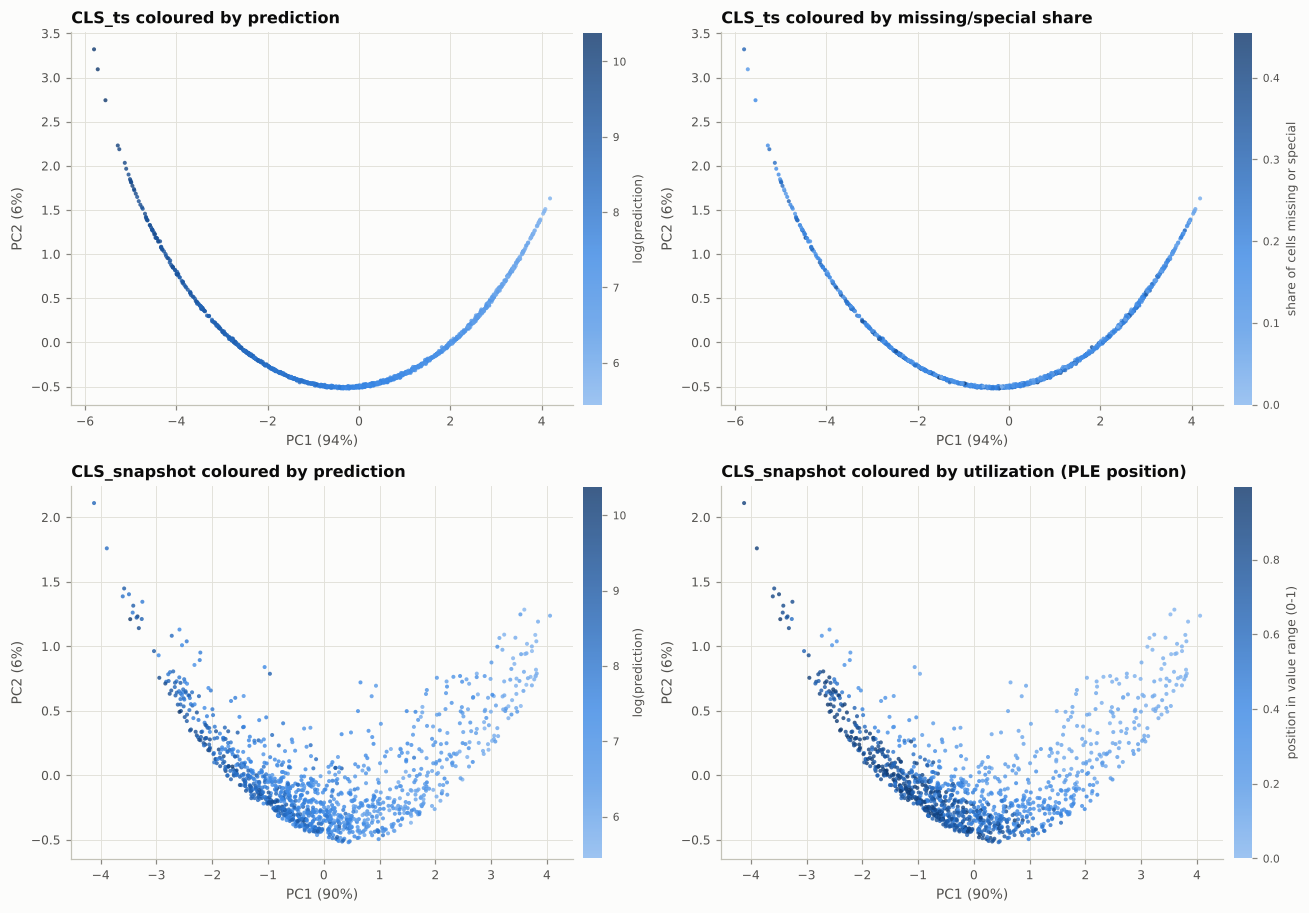

In [4]:
res = I.collect_interpretation(model, val, batch_size=256)
pred = I.to_original(torch.as_tensor(res.link), prep, train_cfg)
state_val = build_state(val_raw.missing, val_raw.special)
nonreg_share = (state_val != 0).mean(axis=(1, 2))
ple_level = {name: val.snapshot[:, j, :g].numpy().mean(1)      # 0..1 position in the variable's range
             for j, (name, g) in enumerate(zip(snap_names, group_sizes))}
print(f"{len(res.index)} records | metrics of this checkpoint:",
      {k: round(v, 3) for k, v in regression_metrics(val_raw.y, pred).items()})

xy_ts, r_ts = I.pca_2d(res.cls["cls_ts"])
xy_sn, r_sn = I.pca_2d(res.cls["cls_snapshot"])
fig, ax = plt.subplots(2, 2, figsize=(12, 8.4))
Z.plot_embedding_scatter(fig, ax[0, 0], xy_ts, np.log(pred), "CLS_ts coloured by prediction", "log(prediction)", r_ts)
Z.plot_embedding_scatter(fig, ax[0, 1], xy_ts, nonreg_share, "CLS_ts coloured by missing/special share",
                         "share of cells missing or special", r_ts)
Z.plot_embedding_scatter(fig, ax[1, 0], xy_sn, np.log(pred), "CLS_snapshot coloured by prediction", "log(prediction)", r_sn)
Z.plot_embedding_scatter(fig, ax[1, 1], xy_sn, ple_level["utilization"],
                         "CLS_snapshot coloured by utilization (PLE position)", "position in value range (0-1)", r_sn)
plt.tight_layout(); plt.show()

**Reading it:**
* `CLS_ts` is almost one-dimensional (PC1 explains 94%) and ordered by the prediction. The encoder compresses the time series into essentially one "level" axis.
* Colouring by the missing/special share shows **no gradient** along that axis. The record embedding is not organised by how much data is missing; on this data, missingness enters through a few small effects (section 5).
* `CLS_snapshot` (PC1 90%) is also ordered by the prediction and tracks *utilization* closely, the most important snapshot variable in section 5.

### Snapshot tokens: how each variable's value range is laid out

Each snapshot variable has its own linear embedding of its PLE vector. Projecting one variable's tokens to two dimensions shows the path its values trace, from the lowest bin to the highest. A straight path means the variable enters roughly linearly. A bent path means different value ranges point in different directions, which is the flexibility PLE buys over a single scalar input.

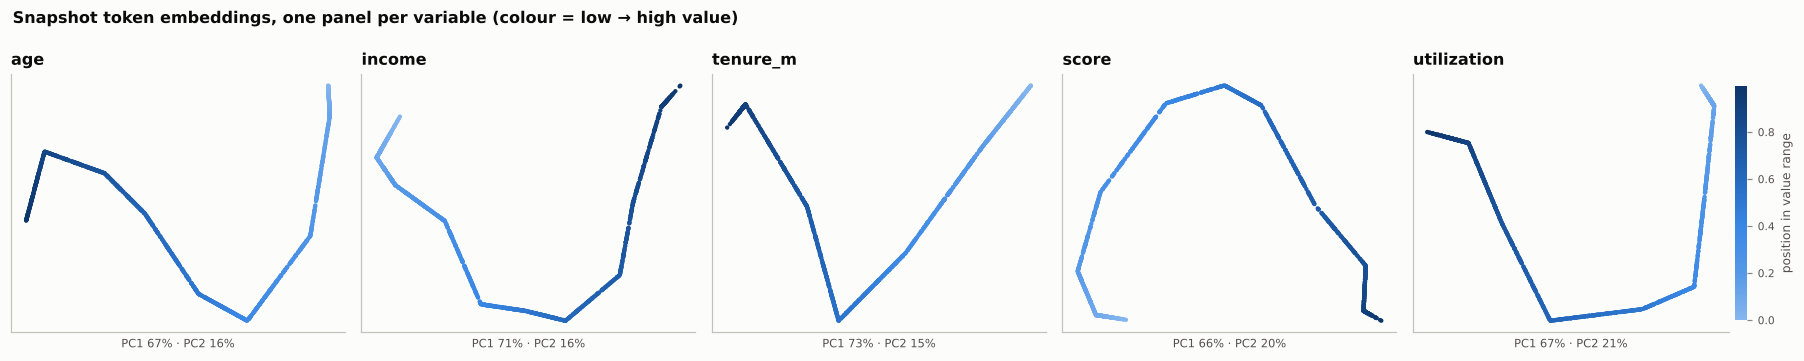

In [5]:
fig, ax = plt.subplots(1, len(snap_names), figsize=(3.3 * len(snap_names), 3.3))
for j, name in enumerate(snap_names):
    xy, r = I.pca_2d(res.snapshot_tokens[:, j, :])
    order = np.argsort(ple_level[name])
    im = ax[j].scatter(xy[order, 0], xy[order, 1], c=ple_level[name][order], cmap=Z.SEQ_MARKS, s=8, linewidths=0)
    ax[j].set_title(name, loc="left"); ax[j].set_xticks([]); ax[j].set_yticks([])
    ax[j].set_xlabel(f"PC1 {100 * r[0]:.0f}% · PC2 {100 * r[1]:.0f}%", fontsize=7.5)
Z.colorbar(fig, im, ax[-1], "position in value range")
fig.suptitle("Snapshot token embeddings, one panel per variable (colour = low → high value)", x=0.01, ha="left",
             fontsize=10.5, fontweight="bold")
plt.tight_layout(); plt.show()

Every variable traces a **bent** path through its bins: *age* and *tenure_m* fold back in a V shape, and *score* runs along an arc. PLE lets each value range point in its own direction, so the model is not forced to treat a variable linearly. Whether a bend is actually *used* is a question for section 5. *tenure_m* has a clear shape here but almost zero permutation importance, matching the generator, where tenure has no effect.

## 3. Attention for one record

The record chosen below has several missing and special cells. The panels show:
1. **Cell states**: what the model received.
2. **Attention rollout to the global CLS.** All layers' attention is combined, counting the residual connection as half of each step. The result is how much of the final time-series embedding traces back to each (variable, patch) token. Patches containing missing or special cells are marked `M` / `S1..S3`.
3. **What the global CLS reads in the last layer**: across variables (through the variable-CLS tokens) and across time (through the time-CLS tokens).

record 100007: y = 2,008, prediction = 2,680; 47% of the rollout reaches patch tokens, the rest stays on the learned CLS tokens


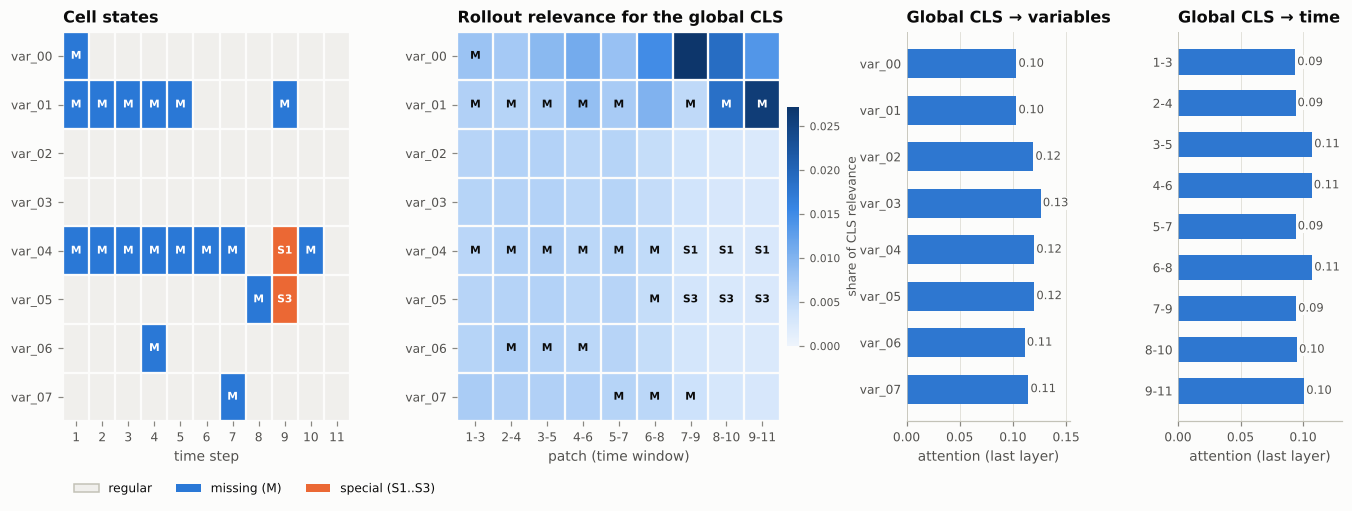

In [6]:
cand = np.where(((state_val == 1).sum((1, 2)) >= 4) & ((state_val >= 2).sum((1, 2)) >= 2))[0]
rec = int(cand[0]) if len(cand) else 0
b = slice(rec, rec + 1)
out1, emb1, det1, maps1 = I.run_with_attention(model, val.x[b].to(DEVICE), val.state[b].to(DEVICE),
                                                val.snapshot[b].to(DEVICE))
roll1 = I.cls_rollout(maps1.var, maps1.time)[0].numpy()
cat1 = I.patch_state_category(det1["state_patches"])[0].cpu().numpy()
summ1 = {k: v[0].numpy() for k, v in I.cls_attention_summary(maps1).items()}
print(f"record {data['val_ids'][rec]}: y = {val_raw.y[rec]:,.0f}, prediction = {pred[rec]:,.0f}; "
      f"{100 * roll1[1:, 1:].sum():.0f}% of the rollout reaches patch tokens, the rest stays on the learned CLS tokens")

fig = plt.figure(figsize=(15, 4.6))
gs = fig.add_gridspec(1, 4, width_ratios=[1.05, 1.25, 0.6, 0.6], wspace=0.45)
ax0, ax1, ax2, ax3 = (fig.add_subplot(gs[i]) for i in range(4))
Z.plot_state_grid(ax0, state_val[rec], var_names, time_steps, "Cell states")
ax0.legend(handles=Z.state_legend(K), loc="upper left", bbox_to_anchor=(0, -0.13), ncol=3)
Z.plot_patch_heatmap(fig, ax1, roll1[1:, 1:], cat1, var_names, patch_labels,
                     "Rollout relevance for the global CLS", "share of CLS relevance")
Z.plot_hbar(ax2, var_names, summ1["global_to_var"], colors=Z.SEQ(0.65), fmt="{:.2f}",
            title="Global CLS → variables", xlabel="attention (last layer)")
Z.plot_hbar(ax3, patch_labels, summ1["global_to_time"], colors=Z.SEQ(0.65), fmt="{:.2f}",
            title="Global CLS → time", xlabel="attention (last layer)")
plt.show()

For this record:
* **Where relevance concentrates.** The rollout falls on **var_00 and var_01 in the most recent windows** (7-9 to 9-11). These are the two drivers built into the synthetic target: the recent level of var_00 and the trend of var_01.
* **Missing patches still count.** Recent var_01 patches that contain a missing cell (`M`) still receive high relevance. The model reads var_01's trend *through* those windows rather than skipping them, which is what value-aware tokens are designed to allow.
* **Learned tokens hold a share.** Only about half of the rollout (47%) reaches patch tokens; the rest stays on the learned CLS tokens, which act as a record-independent baseline.
* **Last-layer attention alone is uninformative.** The global CLS's attention over variables and over time is almost flat. The rollout is informative because it combines both stages over all layers.

### Inside one layer: the two attention stages

* **Across variables, inside one patch column.** The query is either the time-CLS of that patch (top row) or a variable's patch. A row shows which variables that token mixes in at that moment. The column shown contains a special or missing cell, so you can see whether other variables attend to it.
* **Across time, inside one variable's row.** The query is the variable-CLS (top row) or one of its patches. A row shows which time windows it draws on.
* **Time-CLS → variables at every patch** (right). This is the "who matters when" map that feeds the global CLS through the time axis.

All three are drawn **relative to uniform attention**: 1 (gray) means the key gets exactly its equal share, red means more and blue means less. In small models, single layers are often close to uniform, so the raw weights would show one flat colour.

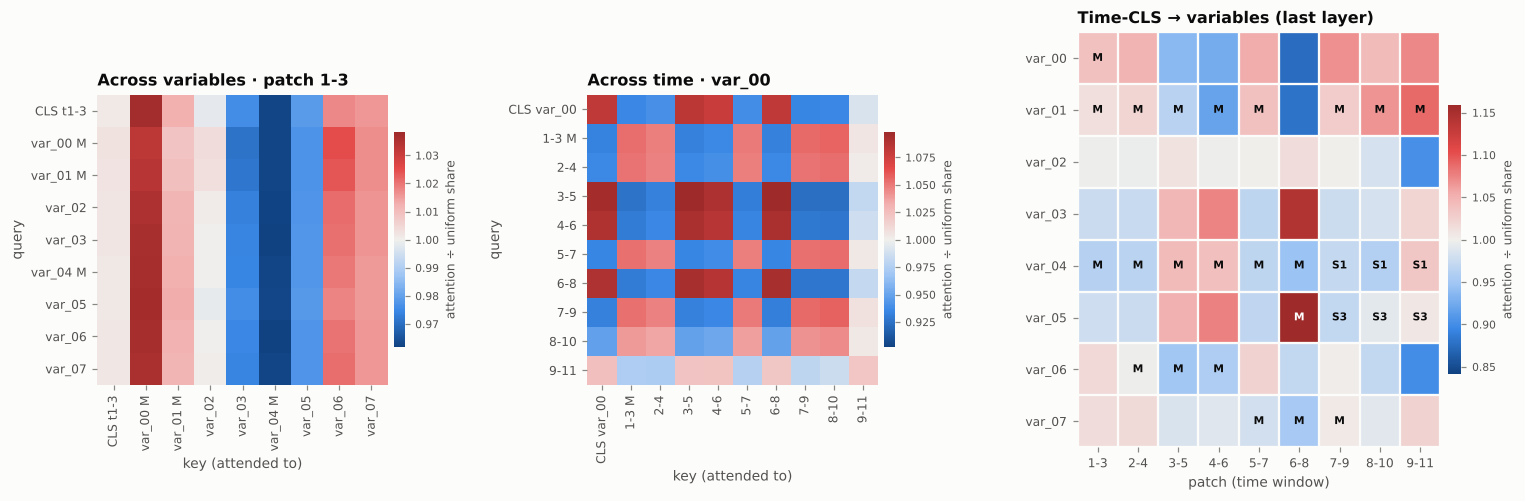

In [7]:
layer = -1
nz = np.argwhere(cat1 > 0)
v_sel, n_sel = (int(nz[0][0]), int(nz[0][1])) if len(nz) else (0, 0)
av = maps1.var[layer][0, n_sel + 1].mean(0).numpy()        # (R, R) inside column n_sel+1
at = maps1.time[layer][0, v_sel + 1].mean(0).numpy()       # (C, C) inside row v_sel+1
g = lambda v, n: Z.state_glyph(int(cat1[v, n]))
lab_v = [f"CLS t{patch_labels[n_sel]}"] + [f"{nm} {g(i, n_sel)}".strip() for i, nm in enumerate(var_names)]
lab_t = [f"CLS {var_names[v_sel]}"] + [f"{pl} {g(v_sel, i)}".strip() for i, pl in enumerate(patch_labels)]

fig = plt.figure(figsize=(16, 4.9))
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 1.25], wspace=0.55)
axs = [fig.add_subplot(gs[i]) for i in range(3)]
Z.plot_attention_matrix(fig, axs[0], av, lab_v, f"Across variables · patch {patch_labels[n_sel]}")
Z.plot_attention_matrix(fig, axs[1], at, lab_t, f"Across time · {var_names[v_sel]}")
Z.plot_patch_heatmap(fig, axs[2], summ1["timecls_to_var"] * (cfg.n_vars + 1), cat1, var_names, patch_labels,
                     "Time-CLS → variables (last layer)", "attention ÷ uniform share", relative=True)
plt.show()

Single attention matrices of this model are **close to uniform**: within ±3% of an equal share across variables and ±8% across time. The time stage shows a periodic pattern that comes from the overlapping 3-step windows (stride 1). Small models with two layers usually spread attention like this and route information gradually. That is why the rollout (section 3 above, 4.1–4.2) and the behaviour checks (section 5) say more than any single matrix.

### Snapshot attention for the same record

The snapshot CLS attends over one token per snapshot variable. The panel shows each head separately and the head average. Heads often specialise, so averaging can hide a variable that one head relies on.

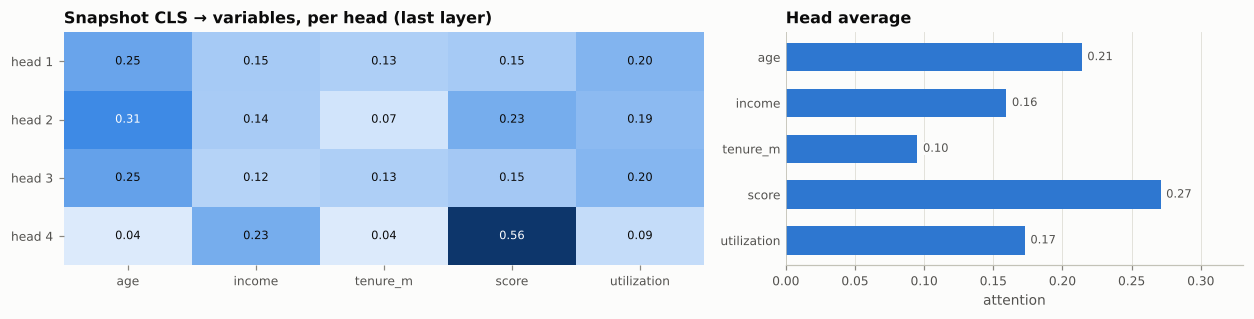

In [8]:
sa = I.snapshot_cls_attention(maps1)[0].numpy()               # (H, S)
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.0), gridspec_kw={"width_ratios": [1.4, 1]})
im = ax[0].imshow(sa, cmap=Z.SEQ, vmin=0, vmax=sa.max(), aspect="auto")
ax[0].set_xticks(range(len(snap_names)), snap_names); ax[0].set_yticks(range(sa.shape[0]), [f"head {h + 1}" for h in range(sa.shape[0])])
for h in range(sa.shape[0]):
    for j in range(sa.shape[1]):
        ax[0].text(j, h, f"{sa[h, j]:.2f}", ha="center", va="center", fontsize=7.5,
                   color="white" if sa[h, j] > 0.55 * sa.max() else Z.INK)
for s in ax[0].spines.values(): s.set_visible(False)
ax[0].set_title("Snapshot CLS → variables, per head (last layer)", loc="left")
Z.plot_hbar(ax[1], snap_names, sa.mean(0), colors=Z.SEQ(0.65), title="Head average", xlabel="attention")
plt.tight_layout(); plt.show()

The heads specialise. Head 4 puts more than half its attention on *score* (0.56), while heads 1–3 spread across *age*, *utilization* and *score*. A head average alone would hide that one head is dedicated to a single variable.

## 4. Across all validation records

**4.1 Do missing/special patches get more or less weight?** For every record, the rollout relevance over patches is normalised to sum to 1. Each patch is labelled by its content: all regular, contains missing, or contains special *k*. **Lift** is the average relevance of a patch of that kind divided by the average relevance of any patch, so 1.0 means no preference.

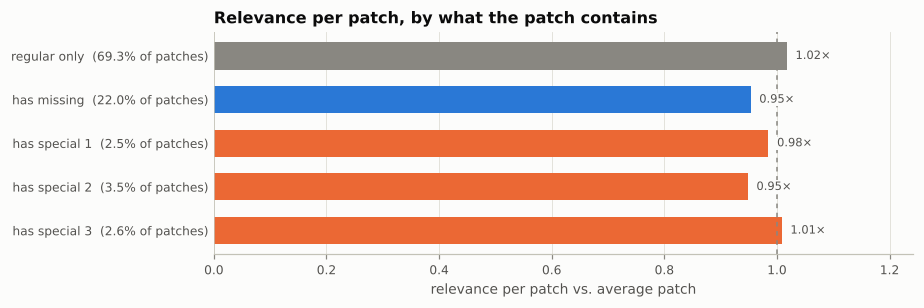

,category,code,n_patches,share_of_patches,share_of_relevance,lift
0,regular only,0,59857,0.693,0.705,1.018
1,has missing,1,19029,0.220,0.210,0.953
2,has special 1,2,2188,0.025,0.025,0.985
3,has special 2,3,3056,0.035,0.034,0.948
4,has special 3,4,2270,0.026,0.027,1.009


In [9]:
lift = I.relevance_by_category(res.patch_relevance, res.patch_category, K)
fig, ax = plt.subplots(figsize=(8.5, 2.9))
Z.plot_category_lift(ax, lift, "Relevance per patch, by what the patch contains")
plt.tight_layout(); plt.show()
lift.round(3)

**No preference here.** Lifts range from 0.95 to 1.02: patches with missing or special cells receive about the same relevance as regular patches. The model neither ignores them nor singles them out. That fits the synthetic data, where missingness acts through a few aggregate effects (more gaps for riskier records, the share of special 2) rather than at particular positions. On real data, a lift well above 1 for a code means the model routes attention through it, and well below 1 means it largely looks past it.

**4.2 Where relevance concentrates and where data is missing.** The left map shows the average relevance per (variable, patch) position. The right map shows how often that position contains a missing or special cell. If the model treated non-regular cells as mere noise, the two maps would be unrelated, or relevance would drop where missingness is frequent.

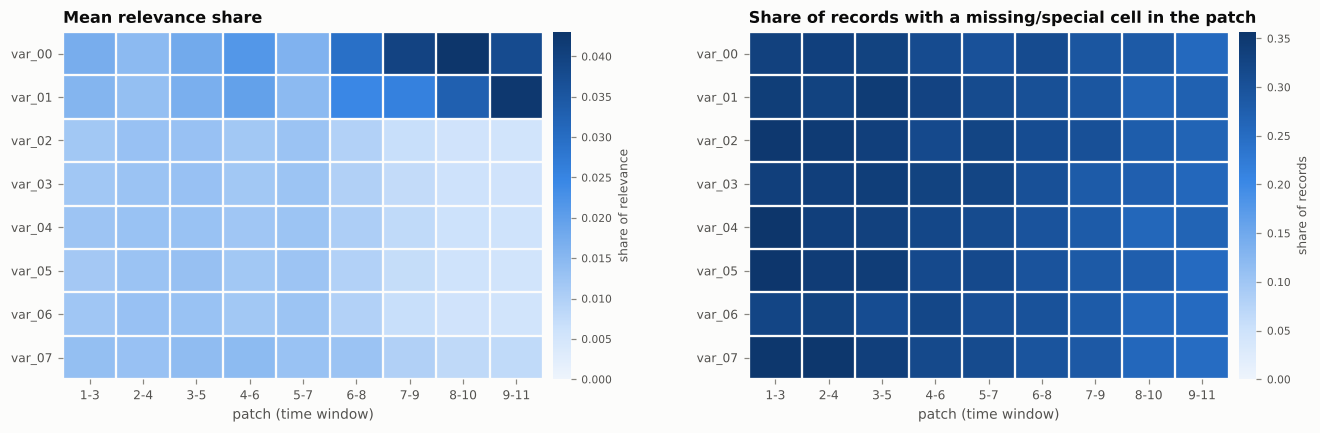

variable,var_00,var_01,var_02,var_03,var_04,var_05,var_06,var_07
share_of_relevance,0.236,0.205,0.090,0.091,0.093,0.090,0.090,0.106
share_patches_not_regular,0.306,0.309,0.314,0.309,0.307,0.309,0.298,0.307


In [10]:
rel = res.patch_relevance / res.patch_relevance.sum(axis=(1, 2), keepdims=True)
fig = plt.figure(figsize=(14, 4.1))
gs = fig.add_gridspec(1, 2, wspace=0.35)
a0, a1 = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])
Z.plot_patch_heatmap(fig, a0, rel.mean(0), None, var_names, patch_labels, "Mean relevance share", "share of relevance")
Z.plot_patch_heatmap(fig, a1, (res.patch_category > 0).mean(0), None, var_names, patch_labels,
                     "Share of records with a missing/special cell in the patch", "share of records")
plt.show()
byvar = I.relevance_by_variable(res.patch_relevance, res.patch_category, var_names)
byvar.assign(share_of_relevance=lambda d: d.share_of_relevance.round(3),
             share_patches_not_regular=lambda d: d.share_patches_not_regular.round(3)).set_index("variable").T

Relevance follows the **signal, not the missingness**:
* **var_00 and var_01** hold 44% of all patch relevance, concentrated in the latest windows.
* **The missingness map is nearly flat:** 25–36% of records per position, slightly higher in early windows, which reflects series that start late.
* **The share of non-regular patches is about the same for every variable** (30–31%), so missingness doesn't explain the ranking.

**4.3 Snapshot variables across records.** These are the attention of the snapshot CLS in the last layer (averaged over heads and records) and the snapshot rollout through all layers. The rollout's share on the CLS itself is excluded and the rest renormalised.

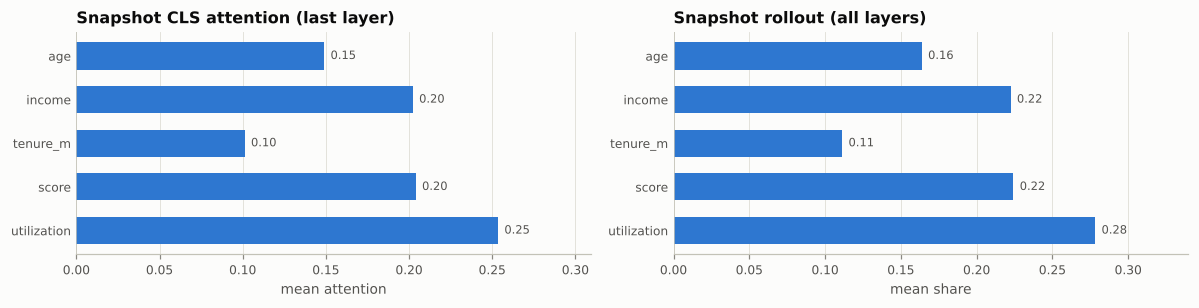

In [11]:
sa_all = res.snapshot_attn.mean(axis=(0, 1))
sr = res.snapshot_rollout[:, 1:] / res.snapshot_rollout[:, 1:].sum(1, keepdims=True)
fig, ax = plt.subplots(1, 2, figsize=(11, 2.9))
Z.plot_hbar(ax[0], snap_names, sa_all, colors=Z.SEQ(0.65), title="Snapshot CLS attention (last layer)", xlabel="mean attention")
Z.plot_hbar(ax[1], snap_names, sr.mean(0), colors=Z.SEQ(0.65), title="Snapshot rollout (all layers)", xlabel="mean share")
plt.tight_layout(); plt.show()

Across records, the snapshot CLS draws most on **utilization** (0.25 attention / 0.28 rollout) and least on **tenure_m** (0.10 / 0.11), with income and score in between. Section 5 checks this against the predictions.

## 5. What the prediction actually depends on

Attention shows information **flow**. These three checks change something and measure the predictions:

* **Branch ablation.** Replace `CLS_ts` or `CLS_snapshot` with its average over records, removing that branch's record-specific information, and measure how much the predictions move and how much RMSE rises.
* **Permutation importance.** Shuffle one input across records: a time-series variable (its 11 values *and* states) or a snapshot variable (its PLE vector). This puts time-series and snapshot variables on one scale.
* **State probe.** Switch randomly chosen regular cells to each missing or special state and measure the direction and size of the effect.

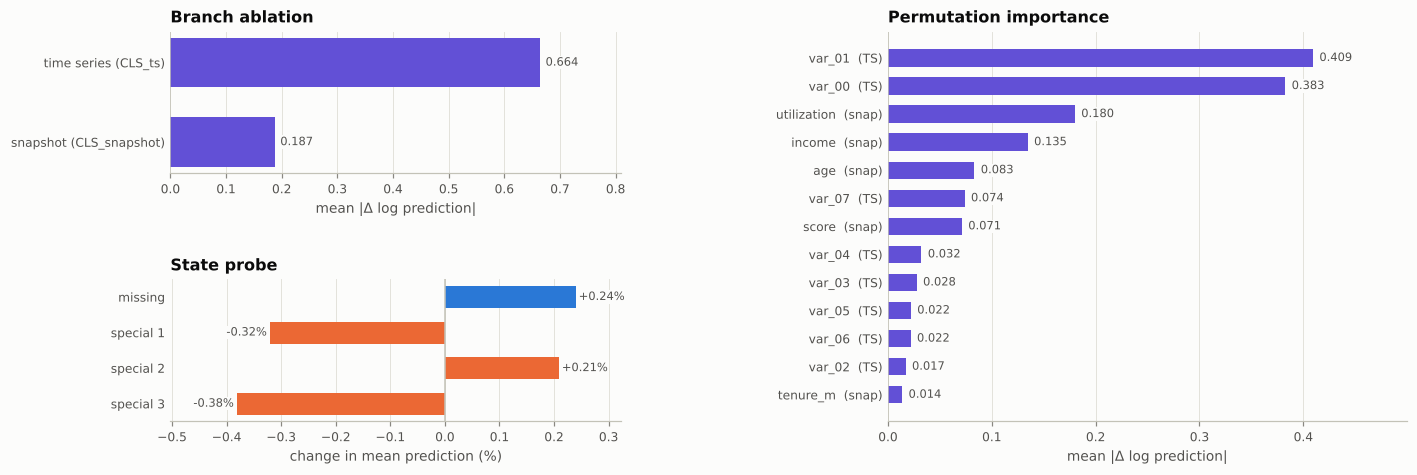

,branch,mean_abs_log_change,rmse_increase_pct
0,cls_ts,0.6642,43.1268
1,cls_snapshot,0.1875,6.7863


,input,kind,mean_abs_log_change,rmse_increase_pct
0,var_01,time series,0.4093,32.1322
1,var_00,time series,0.3826,30.0530
2,utilization,snapshot,0.1800,4.8088
3,income,snapshot,0.1346,2.0859
4,age,snapshot,0.0833,3.1267
5,var_07,time series,0.0738,6.5005
6,score,snapshot,0.0712,3.2287
7,var_04,time series,0.0323,3.1768
8,var_03,time series,0.0277,0.1842
9,var_05,time series,0.0221,0.6375


In [12]:
abl = I.modality_ablation(model, val, prep, train_cfg)
perm = I.permutation_importance(model, val, prep, train_cfg, var_names, snap_names, n_repeats=3)
probe = I.state_probe(model, val, prep, train_cfg, n_cells=600)

fig = plt.figure(figsize=(14.5, 4.6))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 1.15], hspace=0.75, wspace=0.55)
Z.plot_hbar(fig.add_subplot(gs[0, 0]), ["time series (CLS_ts)" if b == "cls_ts" else "snapshot (CLS_snapshot)" for b in abl.branch],
            abl.mean_abs_log_change, title="Branch ablation", xlabel="mean |Δ log prediction|", fmt="{:.3f}")
Z.plot_hbar(fig.add_subplot(gs[1, 0]), list(probe.state), probe.mean_prediction_change_pct,
            colors=[Z.state_color(int(c)) for c in probe.code], title="State probe",
            xlabel="change in mean prediction (%)", fmt="{:+.2f}%")
labels = [f"{r.input}  ({'TS' if r.kind == 'time series' else 'snap'})" for r in perm.itertuples()]
Z.plot_hbar(fig.add_subplot(gs[:, 1]), labels, perm.mean_abs_log_change, title="Permutation importance",
            xlabel="mean |Δ log prediction|", fmt="{:.3f}")
plt.show()
display(abl.round(4))
perm.round(4)

In [13]:
# does the attention-based ranking of time-series variables agree with the permutation ranking?
att_rank = byvar.set_index("variable").share_of_relevance
perm_ts = perm[perm.kind == "time series"].set_index("input").mean_abs_log_change
both = pd.concat({"rollout share": att_rank, "permutation |Δ log pred|": perm_ts}, axis=1)
both["rank (rollout)"] = both["rollout share"].rank(ascending=False).astype(int)
both["rank (permutation)"] = both["permutation |Δ log pred|"].rank(ascending=False).astype(int)
rho = both[["rollout share", "permutation |Δ log pred|"]].corr(method="spearman").iloc[0, 1]
print(f"Spearman rank correlation, rollout vs permutation: {rho:.2f}")
both.sort_values("rank (permutation)").round(4)

Spearman rank correlation, rollout vs permutation: 0.98


,rollout share,permutation |Δ log pred|,rank (rollout),rank (permutation)
var_01,0.2051,0.4093,2,1
var_00,0.2365,0.3826,1,2
var_07,0.1060,0.0738,3,3
var_04,0.0928,0.0323,4,4
var_03,0.0909,0.0277,5,5
var_05,0.0897,0.0221,6,6
var_06,0.0896,0.0218,7,7
var_02,0.0895,0.0170,8,8


**What the prediction depends on** (synthetic data; one seed):
* **Time series vs snapshot.** Removing the record-specific time-series information moves predictions about 3.5× more than removing the snapshot information (mean |Δ log prediction| 0.66 vs 0.19; RMSE +43% vs +7%).
* **Variables.**
  * *var_01* and *var_00* dominate, followed by the snapshot variables *utilization*, *income* and *age*.
  * *tenure_m* is close to zero, which matches the generator.
  * *score* has no direct effect in the generator but correlates with the hidden risk driver, so a modest importance is expected.
* **Missing and special values.**
  * The effects are small: under 0.4% for roughly one changed cell per record out of 88.
  * *missing* and *special 2* push predictions up, as in the generator (riskier records have more gaps, and the share of special 2 raises the target).
  * *special 1* and *special 3*, which have no effect in the generator, move predictions down slightly. Treat that as the noise level for rare codes.
* **Attention vs dependence.**
  * For the time-series variables, rollout and permutation agree almost perfectly (Spearman 0.98).
  * For the snapshot variables they partly disagree: attention gives *score* as much weight as *income*, while permutation ranks it fourth.
  * Rely on section 5 for importance, and on sections 1–4 for *how* the information is represented and routed.

## 6. Reading these views on your data

* **Use the views together.** Rollout and attention show *routing*: which tokens the CLS draws from. Ablation, permutation and the state probe show *dependence*. Agreement between the two (the rank comparison above) is reassuring. Disagreement is common, because a heavily attended token can carry little that changes the output, and the feed-forward layers and the head can amplify small attention weights.
* **Rollout is an approximation.** It averages heads, counts the residual connection as half of each step and ignores the feed-forward layers. Treat it as a map of information flow, not an exact attribution. For per-record attributions with guarantees, gradient-based methods (integrated gradients on the cell values and state embeddings) are the next step. The `details` dict from `run_with_attention` gives you the tensors to attach them to.
* **Missing and special values.** The cell-embedding map shows *how* each code is represented, the relevance lift whether the model *routes* attention through those patches, and the state probe what switching a cell to that code *does* to the prediction. If a rare code has a large effect that contradicts its business meaning, it is a candidate for merging with a similar code or for stronger regularisation (see notebook 03).
* **Scale.** `collect_interpretation(..., max_records=20000)` keeps memory at `O(N · V · Np)`. Permutation importance re-predicts the data `n_repeats` times per input, so run it on a subsample for large data.
* **Correlated inputs.** Permutation importance understates variables whose information is duplicated elsewhere, for example a snapshot variable that is also visible in a time series. Shuffle correlated groups together when you need to.